# Smith-Waterman Local Alignment

Find the best matching substrings without paying for unrelated flanks.

A local alignment can restart at a zero-valued cell. Traceback begins at the overall maximum and stops at zero. Ties can correspond to distinct alignments with the same objective.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from genome_methods import dp_align, show_dp
from Bio.Align import PairwiseAligner

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

GACCTGAA
GACCTCAA
Traceback score 13 | independent score 13.0


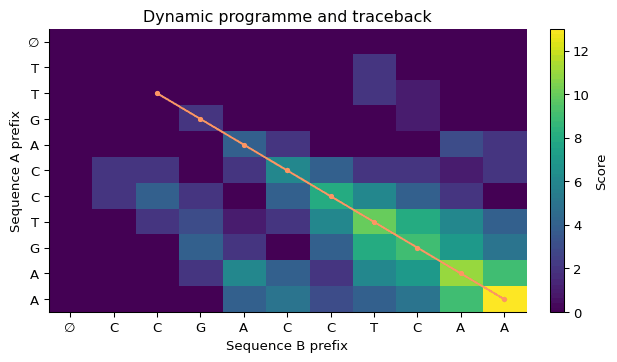

In [2]:
a, b = ("TTGACCTGAA", "CCGACCTCAA")
score, left, right, matrix, path = dp_align(a, b, local=True)
check = PairwiseAligner(
    mode="local", match_score=2, mismatch_score=-1, open_gap_score=-2, extend_gap_score=-2
)
print(left)
print(right)
print("Traceback score", score, "| independent score", check.score(a, b))
assert score == check.score(a, b)
show_dp(a, b, matrix, path)
plt.show()

## Interpreting the result

Read the path from its first to its last cell. A horizontal or vertical run is a gap. The colouring shows why several routes can have the same score.

## Exercise

Force a long unmatched prefix into one input. Compare its effect on the local and global objectives.

## References

[Smith and Waterman, local alignment (1981)](https://doi.org/10.1016/0022-2836(81)90087-5)

[Biopython, pairwise alignments](https://biopython.org/docs/latest/Tutorial/chapter_pairwise.html)